<a href="https://colab.research.google.com/github/her-syntax/EDAB_Assignments/blob/main/EDAB2724_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDAB2724 Assignment 2: Credit Scoring under Class Imbalance

**Group number:** Group 6

### **Objective:**
This notebook addresses Parts A to F of the assignment using the supplied training.csv, OOS test.csv and OOT test.csv datasets.


The analysis follows the assignment's leakage-control requirements:
- Loanref is excluded from predictors.
- Training data is split into development/validation before model selection.
- Missing-value preprocessing is fitted inside pipelines.
- Class imbalance is handled during model fitting.
- The operating threshold is selected using validation data only.
- OOS and OOT are used only after the model, hyperparameters and threshold have been fixed.


## Part A: Data Understanding

Part A requires:
1. Loading and inspecting all three datasets.
2. Confirming dimensions, data types, target values, file roles and aligned predictors.
3. Performing a data-quality audit and explaining cleaning decisions.
4. Quantifying class imbalance.
5. Selecting at least 10 meaningful mortgage-risk variables.


In [ ]:
# Core libraries
import os
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


print("Environment ready.")

Environment ready.


In [ ]:
# Upload the supplied datasets
from google.colab import files

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving OOS test.csv to OOS test.csv
Saving OOT test.csv to OOT test.csv
Saving training.csv to training.csv
Uploaded files: ['OOS test.csv', 'OOT test.csv', 'training.csv']


In [ ]:
# Robust loader for the supplied files.
# If a file is a real CSV, read_csv is used.
# If it is an Excel workbook with a .csv extension, it is copied to .xlsx and read with openpyxl.

def load_supplied_dataset(filename):
    if not os.path.exists(filename):
        raise FileNotFoundError(
            f"{filename} was not found. Please upload the three supplied datasets."
        )

    try:
        return pd.read_csv(filename)
    except (UnicodeDecodeError, pd.errors.ParserError):
        xlsx_name = os.path.splitext(filename)[0] + ".xlsx"
        shutil.copyfile(filename, xlsx_name)
        return pd.read_excel(xlsx_name, engine="openpyxl")

train = load_supplied_dataset("training.csv")
oos = load_supplied_dataset("OOS test.csv")
oot = load_supplied_dataset("OOT test.csv")

print("Training shape:", train.shape)
print("OOS shape:", oos.shape)
print("OOT shape:", oot.shape)

Training shape: (231064, 80)
OOS shape: (232515, 80)
OOT shape: (352788, 80)


In [ ]:
# A1: Structure, target and predictor alignment

dataset_summary = pd.DataFrame({
    "Dataset": ["Training", "OOS", "OOT"],
    "Rows": [len(train), len(oos), len(oot)],
    "Columns": [train.shape[1], oos.shape[1], oot.shape[1]],
    "Defaults": [
        int(train["DFlag"].sum()),
        int(oos["DFlag"].sum()),
        int(oot["DFlag"].sum())
    ],
    "Default rate (%)": [
        train["DFlag"].mean() * 100,
        oos["DFlag"].mean() * 100,
        oot["DFlag"].mean() * 100
    ]
})

display(dataset_summary)

print("\nTarget values:")
for name, df in [("Training", train), ("OOS", oos), ("OOT", oot)]:
    print(name, sorted(df["DFlag"].dropna().unique().tolist()))

print("\nData types - Training:")
display(train.dtypes.value_counts())

print("\nFirst five rows:")
display(train.head())

predictor_sets = [
    set(train.columns) - {"DFlag"},
    set(oos.columns) - {"DFlag"},
    set(oot.columns) - {"DFlag"}
]

print("\nPredictor columns aligned across all datasets:",
      predictor_sets[0] == predictor_sets[1] == predictor_sets[2])

print("Training-only predictors:", sorted(predictor_sets[0] - predictor_sets[1]))
print("OOS-only predictors:", sorted(predictor_sets[1] - predictor_sets[0]))
print("OOT-only predictors:", sorted(predictor_sets[2] - predictor_sets[0]))

,Dataset,Rows,Columns,Defaults,Default rate (%)
0,Training,231064,80,591,0.255773
1,OOS,232515,80,596,0.256328
2,OOT,352788,80,926,0.262481



Target values:
Training [0, 1]
OOS [0, 1]
OOT [0, 1]

Data types - Training:


,count
int64,76
float64,3
object,1



First five rows:


,Loanref,Credit_Score,Mortgage_Insurance,Number_of_units,CLoan_to_value,Debt_to_income,OLoan_to_value,Single_borrower,is_Loan_purpose_purc,is_Loan_purpose_cash,...,is_property_state_TX,is_property_state_UT,is_property_state_VA,is_property_state_VI,is_property_state_VT,is_property_state_WA,is_property_state_WI,is_property_state_WV,is_property_state_WY,DFlag
0,F116Q3164706,723,30,1,95.0,44.0,95.0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,F116Q3287992,728,0,1,74.0,27.0,74.0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
2,F116Q1171011,708,0,1,78.0,28.0,78.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,F116Q4133195,666,0,1,38.0,24.0,38.0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,F116Q4268992,679,0,1,80.0,45.0,80.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Predictor columns aligned across all datasets: True
Training-only predictors: []
OOS-only predictors: []
OOT-only predictors: []


### Part A interpretation

The supplied training dataset is the development sample used for model development, validation, tuning and threshold selection. The OOS dataset is the final out-of-sample evaluation set, while the OOT dataset is the final out-of-time evaluation set. The assignment states that OOS observations come from the same timeline as training, whereas OOT observations come from a later timeline.

DFlag is the target: 1 denotes default and 0 denotes non-default. Loanref is a unique loan identifier and is therefore excluded from predictive modelling.

The predictor columns are checked explicitly above rather than assumed to be aligned.


In [ ]:
# A2: Data-quality audit

def quality_audit(df, name):
    result = pd.DataFrame({
        "Dataset": name,
        "Column": df.columns,
        "dtype": [str(df[c].dtype) for c in df.columns],
        "Missing": [int(df[c].isna().sum()) for c in df.columns],
        "Missing_%": [df[c].isna().mean() * 100 for c in df.columns],
        "Unique": [df[c].nunique(dropna=True) for c in df.columns]
    })
    return result

audit = pd.concat([
    quality_audit(train, "Training"),
    quality_audit(oos, "OOS"),
    quality_audit(oot, "OOT")
], ignore_index=True)

print("Columns with missing values:")
display(audit[audit["Missing"] > 0].sort_values(["Dataset", "Missing"], ascending=[True, False]))

print("Duplicate rows:")
for name, df in [("Training", train), ("OOS", oos), ("OOT", oot)]:
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

print("\nLoanref uniqueness:")
for name, df in [("Training", train), ("OOS", oos), ("OOT", oot)]:
    print(f"{name}: {df['Loanref'].nunique()} unique Loanref values out of {len(df)} rows")

print("\nDFlag missingness:")
for name, df in [("Training", train), ("OOS", oos), ("OOT", oot)]:
    print(f"{name}: {df['DFlag'].isna().sum()} missing target values")

Columns with missing values:


,Dataset,Column,dtype,Missing,Missing_%,Unique
85,OOS,Debt_to_income,float64,11,0.004731,51
84,OOS,CLoan_to_value,float64,3,0.001290,91
86,OOS,OLoan_to_value,float64,3,0.001290,91
165,OOT,Debt_to_income,float64,20,0.005669,50
164,OOT,CLoan_to_value,float64,10,0.002835,100
166,OOT,OLoan_to_value,float64,10,0.002835,92
162,OOT,Mortgage_Insurance,float64,2,0.000567,11
5,Training,Debt_to_income,float64,10,0.004328,50
4,Training,CLoan_to_value,float64,3,0.001298,91
6,Training,OLoan_to_value,float64,3,0.001298,90


Duplicate rows:
Training: 0 duplicate rows
OOS: 0 duplicate rows
OOT: 0 duplicate rows

Loanref uniqueness:
Training: 231064 unique Loanref values out of 231064 rows
OOS: 232515 unique Loanref values out of 232515 rows
OOT: 352788 unique Loanref values out of 352788 rows

DFlag missingness:
Training: 0 missing target values
OOS: 0 missing target values
OOT: 0 missing target values


### Data-quality decisions

- Loanref is retained for identification/audit purposes but excluded from model predictors because it is a unique identifier.
- Missing predictor values are **not** deleted automatically. Because the assignment contains a very small number of missing values, the modelling pipeline uses median imputation fitted on training/development data only.
- No rows from OOS or OOT are used to fit preprocessing or tune the model.
- DFlag is treated as the binary target and is not imputed.
- Duplicate observations are reported rather than silently removed; any removal would need a dataset-specific justification.


In [ ]:
# A3: Class imbalance

imbalance_rows = []

for name, df in [("Training", train), ("OOS", oos), ("OOT", oot)]:
    y = df["DFlag"].dropna().astype(int)
    non_default = int((y == 0).sum())
    default = int((y == 1).sum())
    total = len(y)

    imbalance_rows.append({
        "Dataset": name,
        "Non-default": non_default,
        "Default": default,
        "Non-default %": non_default / total * 100,
        "Default %": default / total * 100,
        "Imbalance ratio (non-default:default)": non_default / default
    })

imbalance_table = pd.DataFrame(imbalance_rows)
display(imbalance_table.round(4))

,Dataset,Non-default,Default,Non-default %,Default %,Imbalance ratio (non-default:default)
0,Training,230473,591,99.7442,0.2558,389.9712
1,OOS,231919,596,99.7437,0.2563,389.1258
2,OOT,351862,926,99.7375,0.2625,379.9806


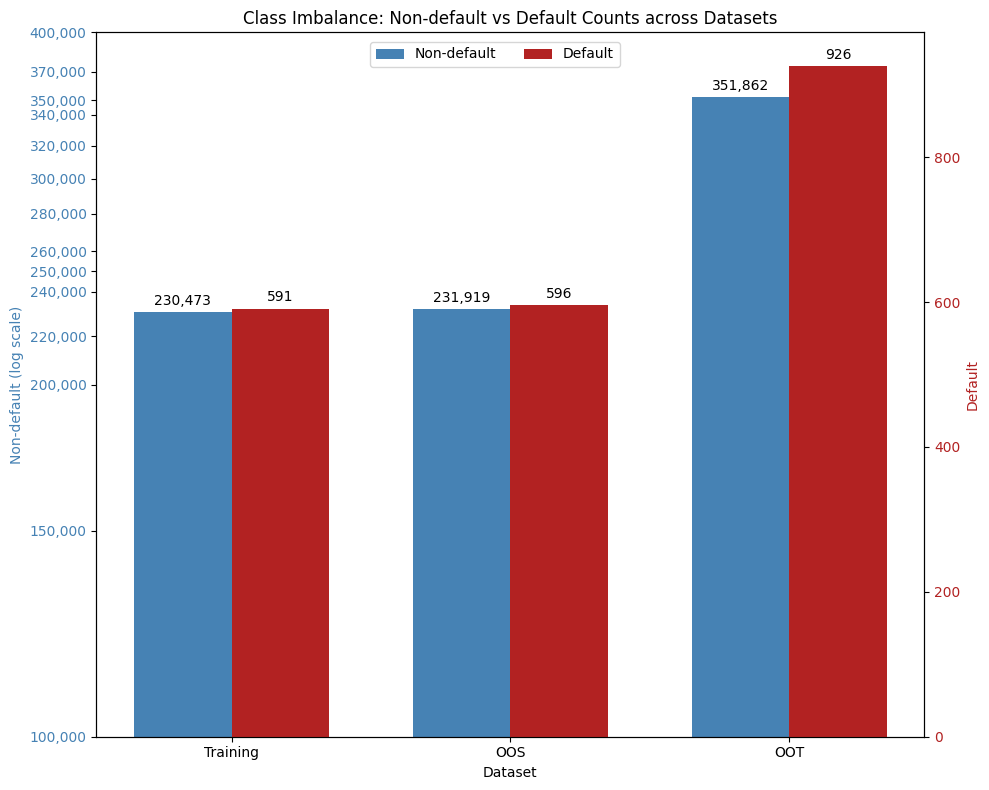

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter, FixedLocator

fig, ax1 = plt.subplots(figsize=(10, 8))

bar_width = 0.35
index = np.arange(len(imbalance_table['Dataset']))

# Plot Non-default counts on primary y-axis
bars1 = ax1.bar(index - bar_width/2, imbalance_table['Non-default'], bar_width, label='Non-default', color='steelblue')
ax1.set_xlabel('Dataset')
ax1.set_ylabel('Non-default (log scale)', color='steelblue')
ax1.set_yscale('log')
ax1.tick_params(axis='y', labelcolor='steelblue')

# Explicitly set y-axis limits to better control tick placement
min_count = imbalance_table['Non-default'].min()
max_count = imbalance_table['Non-default'].max()
ax1.set_ylim(bottom=100000, top=400000) # Set limits to encompass the data and desired ticks

# Custom formatter for the log-scaled y-axis to display full numbers
def format_func(value, tick_pos):
    return '{:,.0f}'.format(value)

ax1.yaxis.set_major_formatter(FuncFormatter(format_func))
# Set major ticks manually to ensure desired labels are present and dense enough
ax1.yaxis.set_major_locator(FixedLocator([100000, 150000, 200000, 220000, 240000, 250000, 260000, 280000, 300000, 320000, 340000, 350000, 370000, 400000]))

# Create a second y-axis for Default counts
ax2 = ax1.twinx()
bars2 = ax2.bar(index + bar_width/2, imbalance_table['Default'], bar_width, label='Default', color='firebrick')
ax2.set_ylabel('Default', color='firebrick')
ax2.tick_params(axis='y', labelcolor='firebrick')

# Set x-axis labels
ax1.set_xticks(index)
ax1.set_xticklabels(imbalance_table['Dataset'])

# Add counts on top of bars
def autolabel(bars, ax):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{int(height):,}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(bars1, ax1)
autolabel(bars2, ax2)

# Add title and legend
plt.title('Class Imbalance: Non-default vs Default Counts across Datasets')
# Re-adding the legend, placed at the top center
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2)

plt.tight_layout()
plt.show()

### Class-imbalance interpretation

The default class represents only about 0.26% of observations in each supplied dataset. This is a severe class imbalance problem. A classifier that predicts nearly every loan as non-default can obtain extremely high accuracy while detecting very few actual defaults.

Consequently, accuracy cannot be used as the main model-selection criterion. Precision, recall, F1-score, ROC-AUC and especially PR-AUC/AUPR are needed to assess performance on the rare default class.


In [ ]:
# A4: At least 10 meaningful mortgage-risk variables

important_variables = [
    ("Credit_Score", "Borrower credit score; lower values generally indicate weaker credit quality."),
    ("Debt_to_income", "Debt-to-income measure; higher values indicate greater debt burden relative to income."),
    ("CLoan_to_value", "Current loan-to-value measure; higher leverage can increase loss/default risk."),
    ("OLoan_to_value", "Original loan-to-value measure; captures leverage at origination."),
    ("Mortgage_Insurance", "Mortgage-insurance related variable; can distinguish loans with different leverage/insurance characteristics."),
    ("Number_of_units", "Number of units associated with the property; property structure can affect risk."),
    ("Single_borrower", "Indicator of whether the mortgage has a single borrower."),
    ("is_Loan_purpose_purc", "Purchase-loan indicator."),
    ("is_Loan_purpose_cash", "Cash-out refinance indicator."),
    ("is_Loan_purpose_noca", "No-cash-out refinance indicator."),
    ("is_First_time_homeowner", "First-time homeowner indicator."),
    ("is_Occupancy_status_prim", "Primary-residence occupancy indicator."),
    ("is_Origination_channel_reta", "Retail origination-channel indicator."),
    ("is_Property_type_sing", "Single-family property-type indicator.")
]

important_variable_table = pd.DataFrame(
    important_variables, columns=["Variable", "Why it may matter for default risk"]
)

display(important_variable_table)

,Variable,Why it may matter for default risk
0,Credit_Score,Borrower credit score; lower values generally ...
1,Debt_to_income,Debt-to-income measure; higher values indicate...
2,CLoan_to_value,Current loan-to-value measure; higher leverage...
3,OLoan_to_value,Original loan-to-value measure; captures lever...
4,Mortgage_Insurance,Mortgage-insurance related variable; can disti...
5,Number_of_units,Number of units associated with the property; ...
6,Single_borrower,Indicator of whether the mortgage has a single...
7,is_Loan_purpose_purc,Purchase-loan indicator.
8,is_Loan_purpose_cash,Cash-out refinance indicator.
9,is_Loan_purpose_noca,No-cash-out refinance indicator.


# Part B: Exploratory Data Analysis (EDA)

The EDA examines default behaviour and whether the later OOT population differs from the development data. The plots below are selected to answer the questions in the brief rather than simply generate visuals.


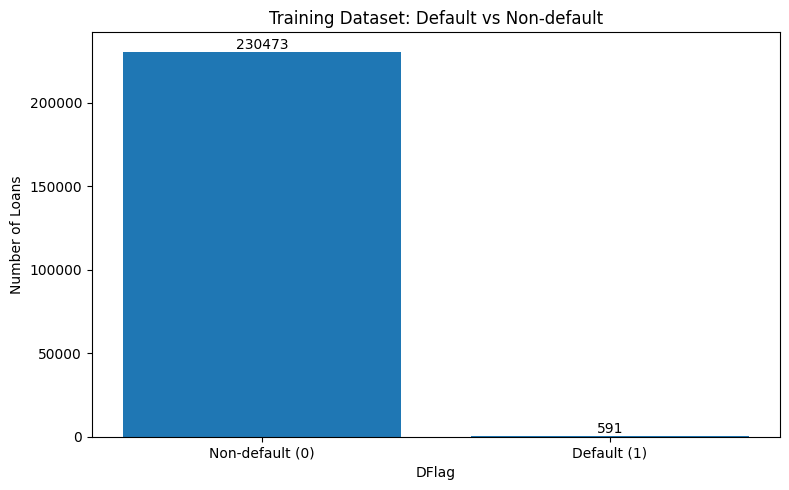

In [ ]:
# Visualise default vs non-default observations

counts = train["DFlag"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

# Create the bar plot
bars = plt.bar(
    ["Non-default (0)", "Default (1)"],
    counts.values
)

# Add the count values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, yval, ha='center', va='bottom')

plt.title("Training Dataset: Default vs Non-default")
plt.xlabel("DFlag")
plt.ylabel("Number of Loans")
# Removed: plt.yscale('log') # Apply log scale to y-axis

plt.tight_layout()
plt.show()

### B1 interpretation

The graph shows an extremely large difference between the number of non-default and default observations. Defaults are a tiny minority of the dataset. Therefore, accuracy is unreliable as a standalone performance measure: a model can classify almost all observations as non-default and still achieve very high accuracy while failing to identify borrowers who default. Minority-class recall, precision, F1 and PR-AUC are therefore particularly important.


In [ ]:
# B2: Numerical risk variables by default status

risk_variables = [
    "Credit_Score",
    "Debt_to_income",
    "CLoan_to_value",
    "OLoan_to_value"
]

numeric_risk_summary = []

for variable in risk_variables:
    grouped = train.groupby("DFlag")[variable].agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std"
    ).reset_index()

    grouped["Variable"] = variable
    numeric_risk_summary.append(grouped)

numeric_risk_summary = pd.concat(numeric_risk_summary, ignore_index=True)
display(numeric_risk_summary[["Variable", "DFlag", "Count", "Mean", "Median", "Std"]].round(2))

,Variable,DFlag,Count,Mean,Median,Std
0,Credit_Score,0,230473,695.05,701.0,25.74
1,Credit_Score,1,591,678.15,680.0,30.62
2,Debt_to_income,0,230463,35.83,37.0,8.45
3,Debt_to_income,1,591,37.78,40.0,7.48
4,CLoan_to_value,0,230470,75.14,80.0,15.36
5,CLoan_to_value,1,591,79.04,80.0,14.12
6,OLoan_to_value,0,230470,74.69,79.0,15.45
7,OLoan_to_value,1,591,78.61,80.0,14.28


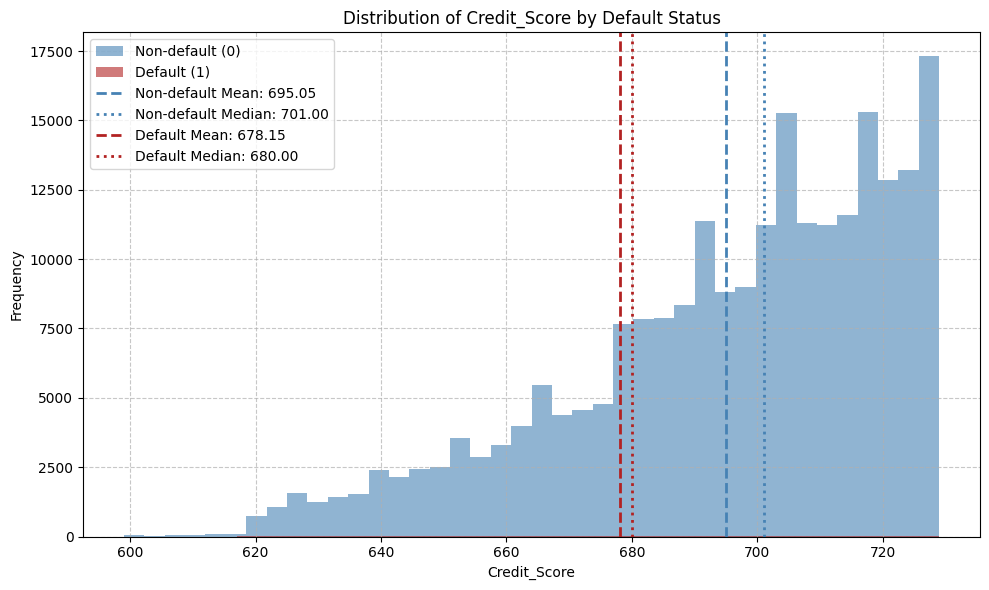

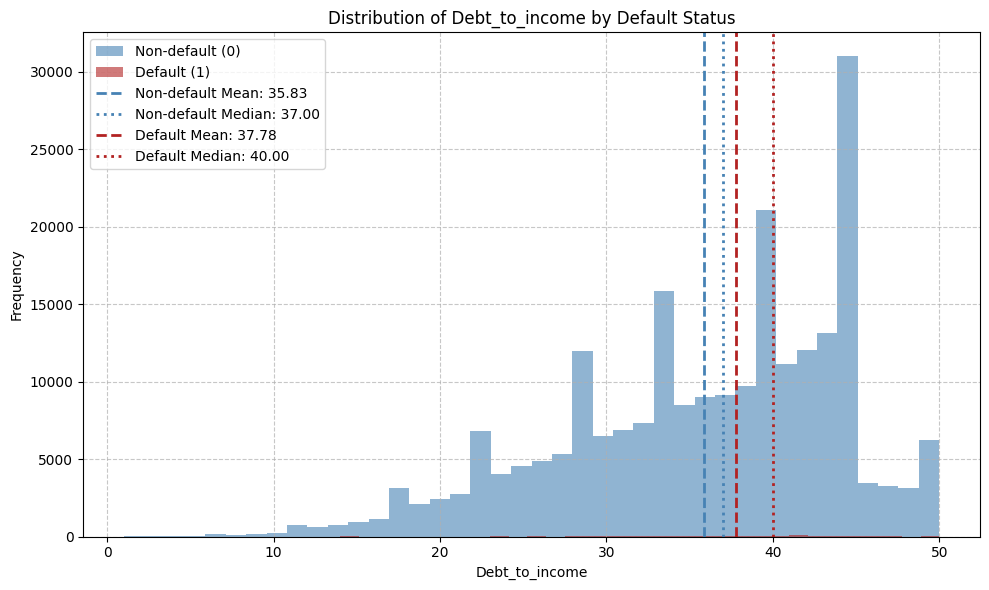

In [ ]:
selected_risk_variables = [
    "Credit_Score",
    "Debt_to_income"
]

for variable in selected_risk_variables:

    plt.figure(figsize=(10, 6)) # Create figure

    # Plot histograms for non-default (DFlag = 0)
    plt.hist(train[train["DFlag"] == 0][variable].dropna(),
             bins=40, alpha=0.6, label='Non-default (0)', color='steelblue')

    # Plot histograms for default (DFlag = 1)
    plt.hist(train[train["DFlag"] == 1][variable].dropna(),
             bins=40, alpha=0.6, label='Default (1)', color='firebrick')

    # Retrieve mean and median values from numeric_risk_summary
    mean_non_default = numeric_risk_summary[(numeric_risk_summary['Variable'] == variable) & (numeric_risk_summary['DFlag'] == 0)]['Mean'].iloc[0]
    median_non_default = numeric_risk_summary[(numeric_risk_summary['Variable'] == variable) & (numeric_risk_summary['DFlag'] == 0)]['Median'].iloc[0]

    mean_default = numeric_risk_summary[(numeric_risk_summary['Variable'] == variable) & (numeric_risk_summary['DFlag'] == 1)]['Mean'].iloc[0]
    median_default = numeric_risk_summary[(numeric_risk_summary['Variable'] == variable) & (numeric_risk_summary['DFlag'] == 1)]['Median'].iloc[0]

    # Add vertical lines for mean and median for non-default
    plt.axvline(mean_non_default, color='steelblue', linestyle='dashed', linewidth=2, label=f'Non-default Mean: {mean_non_default:.2f}')
    plt.axvline(median_non_default, color='steelblue', linestyle='dotted', linewidth=2, label=f'Non-default Median: {median_non_default:.2f}')

    # Add vertical lines for mean and median for default
    plt.axvline(mean_default, color='firebrick', linestyle='dashed', linewidth=2, label=f'Default Mean: {mean_default:.2f}')
    plt.axvline(median_default, color='firebrick', linestyle='dotted', linewidth=2, label=f'Default Median: {median_default:.2f}')

    # Set titles and labels
    plt.title(f"Distribution of {variable} by Default Status")
    plt.xlabel(variable)
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

### B2 interpretation: Numerical Risk Variable Differentials

The histograms and summary table illustrate clear risk differentials for key numerical variables between defaulters and non-defaulters:

*   **Credit Score:** Defaulting accounts show a significant deficit in Credit Score, averaging ~678.15 (median ~680.0) compared to non-defaulters at ~695.05 (median ~701.0). The histograms clearly show that the distribution for defaulters is shifted towards lower credit scores, with a larger proportion of defaulters falling into the lower score ranges compared to non-defaulters.
*   **Debt-to-Income (DTI):** Default loans exhibit higher DTI leverage, with an average of ~37.78% (median ~40.0) versus non-defaulters at ~35.83% (median ~37.0). The histograms confirm that defaulters generally have higher debt-to-income ratios, with their distribution peaking at higher DTI values.

These differences highlight that lower credit scores and higher debt burdens are strongly associated with higher observed default risk. This analysis focuses on associations within the training data and should not be interpreted as definitive proof of causation.

In [ ]:
# B3: Default rates for three indicator-variable groups

indicator_groups = {
    "Loan purpose": [c for c in train.columns if "Loan_purpose" in c],
    "First-time homeowner": [c for c in train.columns if "First_time_homeowner" in c],
    "Occupancy status": [c for c in train.columns if "Occupancy_status" in c]
}

def indicator_default_rates(df, columns):
    rows = []
    for col in columns:
        subset = df[df[col] == 1]
        rows.append({
            "Indicator": col,
            "Observations": len(subset),
            "Defaults": int(subset["DFlag"].sum()),
            "Default rate (%)": subset["DFlag"].mean() * 100 if len(subset) else np.nan
        })
    return pd.DataFrame(rows)

for group_name, columns in indicator_groups.items():
    print(f"\n{group_name}")
    result = indicator_default_rates(train, columns)
    display(result.sort_values("Default rate (%)", ascending=False).round(4))


Loan purpose


,Indicator,Observations,Defaults,Default rate (%)
0,is_Loan_purpose_purc,101310,326,0.3218
1,is_Loan_purpose_cash,67858,166,0.2446
2,is_Loan_purpose_noca,61896,99,0.1599



First-time homeowner


,Indicator,Observations,Defaults,Default rate (%)
0,is_First_time_homeowner,41739,145,0.3474
1,is_First_time_homeowner_No,50172,171,0.3408
2,is_First_time_homeowner_miss,139153,275,0.1976



Occupancy status


,Indicator,Observations,Defaults,Default rate (%)
0,is_Occupancy_status_prim,211925,568,0.2680
1,is_Occupancy_status_inve,13589,18,0.1325
2,is_Occupancy_status_seco,5550,5,0.0901


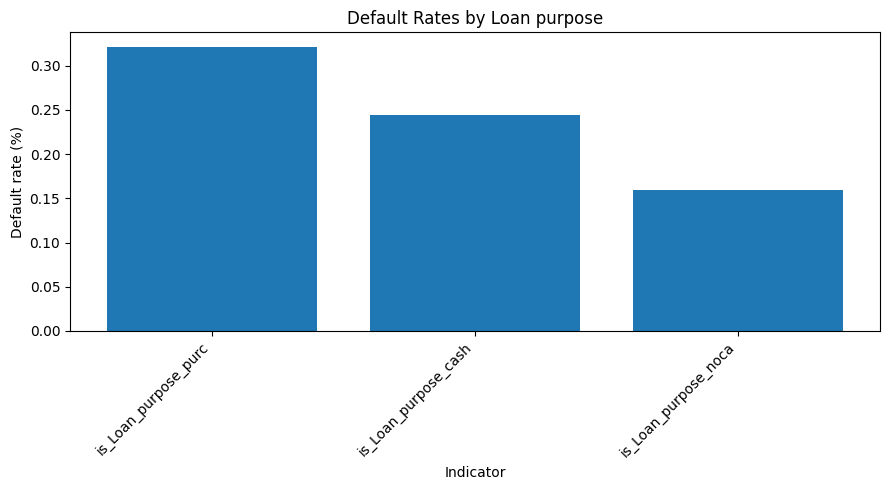

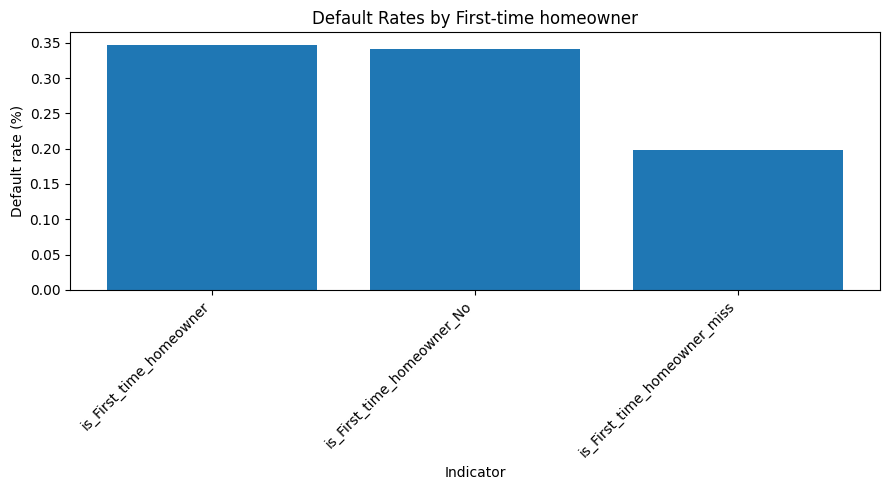

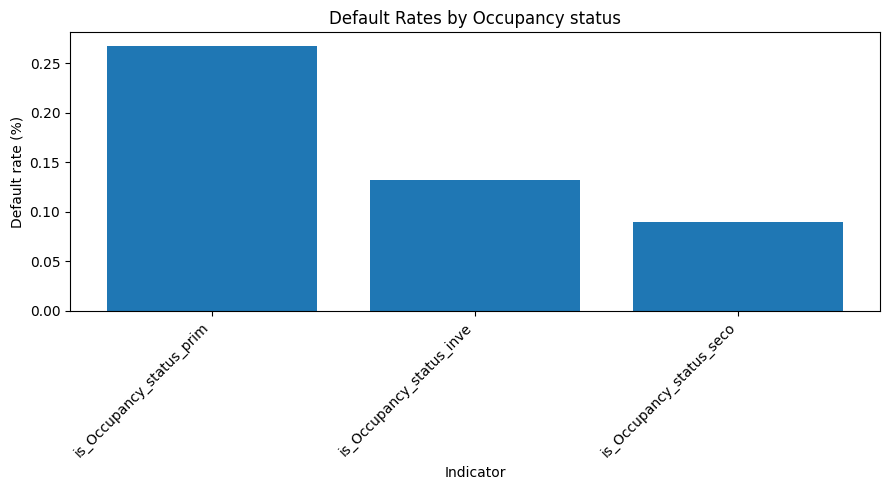

In [ ]:
# B3: Visual comparison of indicator default rates

for group_name, columns in indicator_groups.items():
    result = indicator_default_rates(train, columns).dropna()

    plt.figure(figsize=(9, 5))
    plt.bar(result["Indicator"], result["Default rate (%)"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Default rate (%)")
    plt.xlabel("Indicator")
    plt.title(f"Default Rates by {group_name}")
    plt.tight_layout()
    plt.show()

### B3 interpretation

Default rates differ across the selected loan-purpose, first-time-homeowner and occupancy indicators. These differences provide useful segmentation information for risk analysis. Because the default event is rare, small numerical differences should be interpreted carefully and should not be treated as causal effects.


### B3 interpretation: Loan Purpose Default Rates

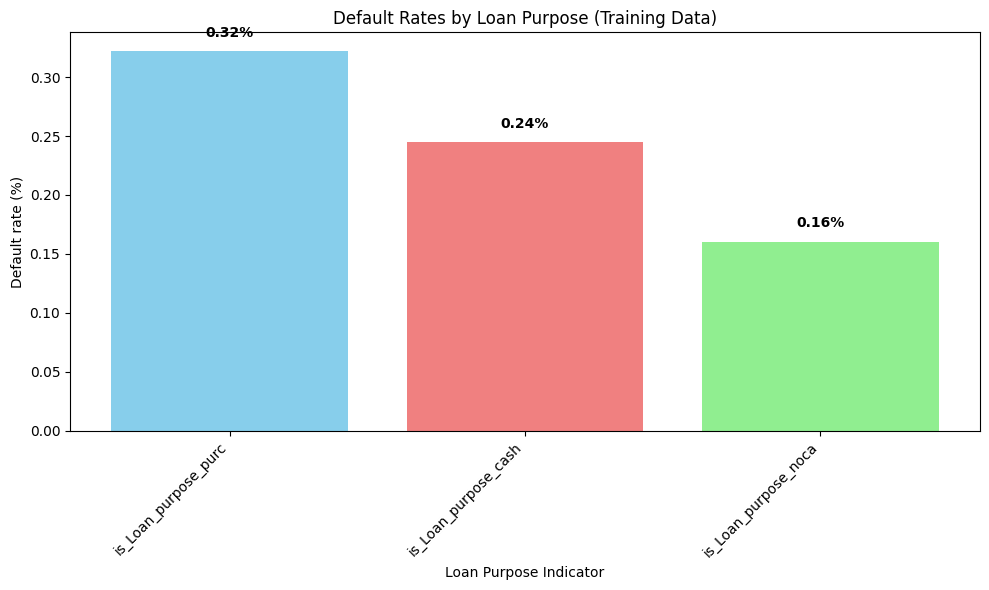

In [ ]:
loan_purpose_columns = indicator_groups["Loan purpose"]
loan_purpose_rates = indicator_default_rates(train, loan_purpose_columns).dropna()

plt.figure(figsize=(10, 6))
bars = plt.bar(loan_purpose_rates["Indicator"], loan_purpose_rates["Default rate (%)"], color=['skyblue', 'lightcoral', 'lightgreen'])

# Add annotations for specific rates as per user's interpretation
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.2f}%',
             ha='center', va='bottom', fontsize=10, weight='bold')

plt.xticks(rotation=45, ha="right")
plt.ylabel("Default rate (%)")
plt.xlabel("Loan Purpose Indicator")
plt.title("Default Rates by Loan Purpose (Training Data)")
plt.tight_layout()
plt.show()

# Further enhance B3 interpretation markdown cell to add the categorical default segments insights


In [ ]:
# B4: Train/OOS/OOT distribution comparison for at least five predictors

important_predictors = [
    "Credit_Score",
    "Debt_to_income",
    "CLoan_to_value",
    "OLoan_to_value",
    "Mortgage_Insurance"
]

distribution_rows = []

for variable in important_predictors:
    for dataset_name, df in [("Training", train), ("OOS", oos), ("OOT", oot)]:
        s = pd.to_numeric(df[variable], errors="coerce")
        distribution_rows.append({
            "Variable": variable,
            "Dataset": dataset_name,
            "Mean": s.mean(),
            "Median": s.median(),
            "Std": s.std(),
            "Min": s.min(),
            "Max": s.max()
        })

distribution_summary = pd.DataFrame(distribution_rows)
display(distribution_summary.round(2))

,Variable,Dataset,Mean,Median,Std,Min,Max
0,Credit_Score,Training,695.01,701.0,25.76,599.0,729.0
1,Credit_Score,OOS,694.97,700.0,25.79,518.0,729.0
2,Credit_Score,OOT,692.59,699.0,27.52,600.0,729.0
3,Debt_to_income,Training,35.84,37.0,8.44,1.0,50.0
4,Debt_to_income,OOS,35.86,37.0,8.44,1.0,51.0
5,Debt_to_income,OOT,37.10,39.0,8.68,1.0,50.0
6,CLoan_to_value,Training,75.15,80.0,15.36,6.0,108.0
7,CLoan_to_value,OOS,75.16,80.0,15.33,6.0,97.0
8,CLoan_to_value,OOT,75.21,80.0,16.45,6.0,105.0
9,OLoan_to_value,Training,74.70,79.0,15.45,6.0,95.0


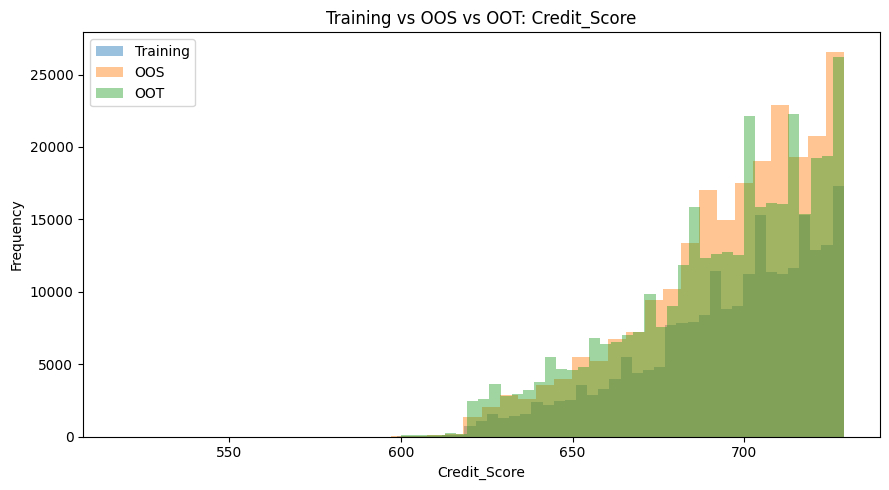

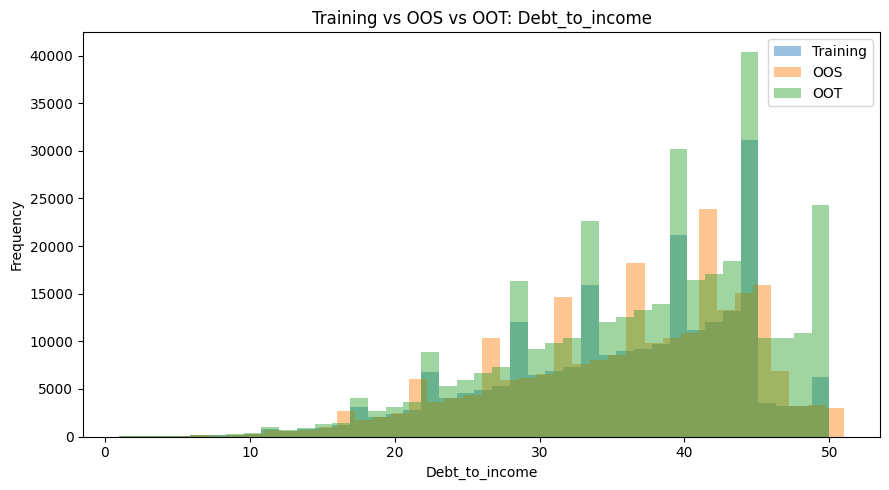

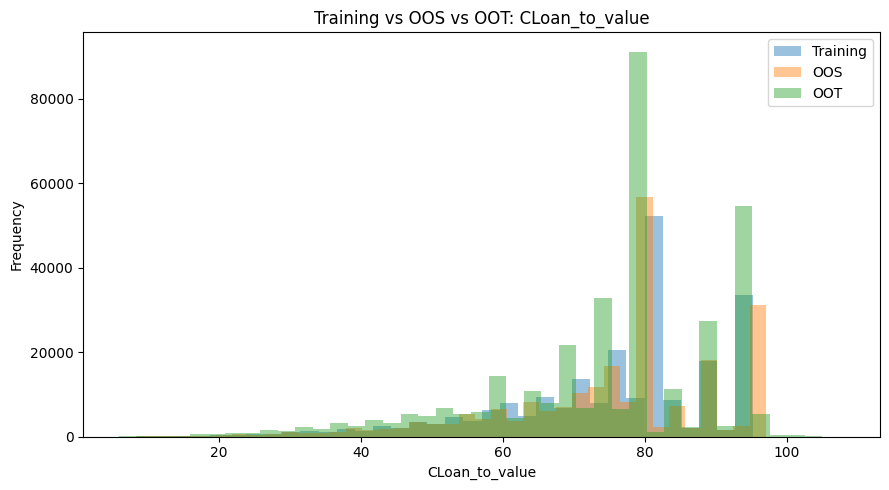

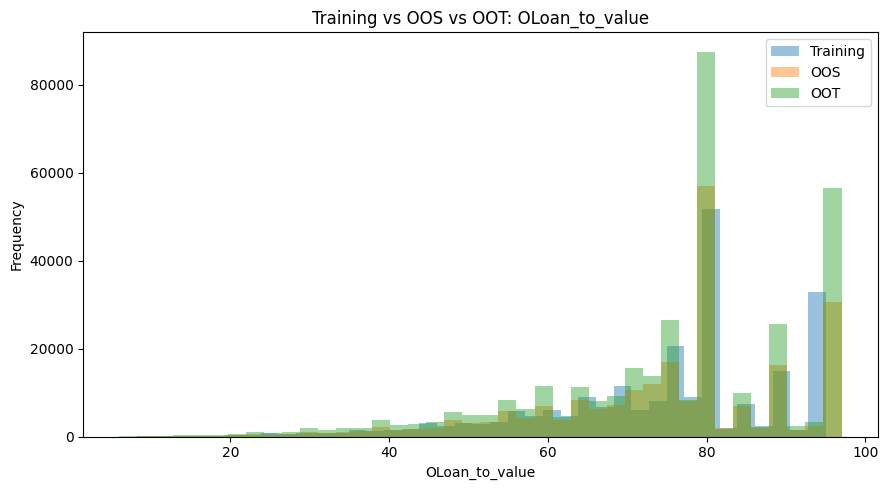

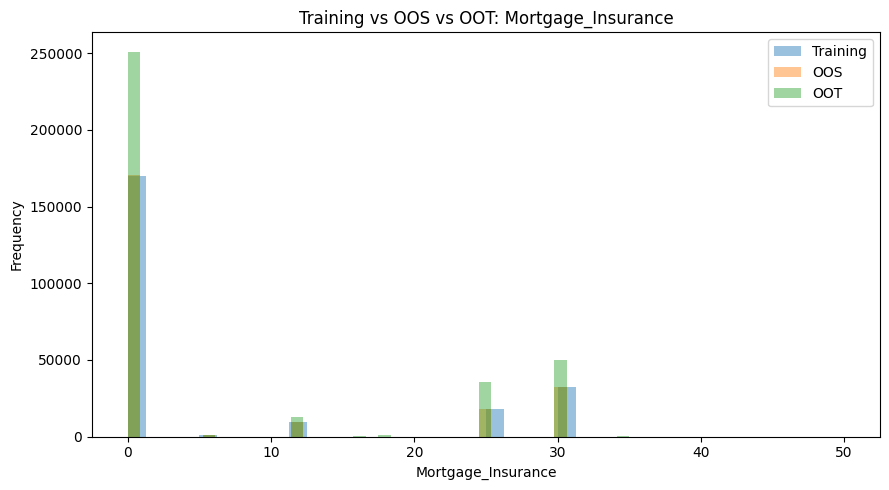

In [ ]:
# B4: Overlaid distributions

for variable in important_predictors:
    plt.figure(figsize=(9, 5))

    for name, df in [("Training", train), ("OOS", oos), ("OOT", oot)]:
        values = pd.to_numeric(df[variable], errors="coerce").dropna()
        plt.hist(values, bins=40, alpha=0.45, label=name)

    plt.title(f"Training vs OOS vs OOT: {variable}")
    plt.xlabel(variable)
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

### B4 interpretation

Training and OOS distributions are expected to be broadly comparable because OOS comes from the same timeline as the development data. The OOT distributions are checked separately because they represent a later population. Evidence of a shift should be based on the observed summary statistics and distribution plots rather than simply on the fact that OOT is later.

The supplied data show broadly stable Training/OOS distributions, while OOT shows modest movement in some important variables, particularly credit score, debt-to-income and mortgage-insurance values. This suggests that the deployed model should be monitored for temporal drift.


### B5: EDA conclusion

The EDA shows severe class imbalance, making accuracy alone unsuitable for judging default prediction. Defaults are associated with lower credit scores and higher debt-to-income and loan-to-value measures. Default rates also vary across loan-purpose, homeowner and occupancy segments. Training and OOS populations are broadly similar, while OOT shows modest distributional movement in some risk variables. These findings motivate imbalance-aware modelling, PR-AUC-based evaluation and explicit monitoring for population drift.


# Part C: Predictive Modelling

**Main candidate:** Random Forest with class weighting.

**Benchmarks:** Logistic Regression and Decision Tree.

The main model is tuned using the development portion of training.csv only. A validation set is reserved for threshold selection. OOS and OOT are not used during model selection or threshold selection.


In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, log_loss, roc_curve, precision_recall_curve,
    fbeta_score
)

RANDOM_STATE = 42 # Defining RANDOM_STATE for reproducibility

# Predictors: explicitly exclude the identifier and target
features = [c for c in train.columns if c not in ["Loanref", "DFlag"]]

X = train[features].replace([np.inf, -np.inf], np.nan)
y = train["DFlag"].astype(int)

X_dev, X_val, y_dev, y_val = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Development:", X_dev.shape)
print("Validation:", X_val.shape)
print("Default rate in development:", y_dev.mean())
print("Default rate in validation:", y_val.mean())

Development: (184851, 78)
Validation: (46213, 78)
Default rate in development: 0.0025588176423173258
Default rate in validation: 0.002553394066604635


In [ ]:
# C1: Benchmark models and main model setup

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=500,
        solver="liblinear",
        random_state=RANDOM_STATE
    ))
])

tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=6,
        min_samples_leaf=20,
        random_state=RANDOM_STATE
    ))
])

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced_subsample",
        n_estimators=80,
        max_depth=10,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

# Train initial models on development data only
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model
}

validation_scores = []

for name, model in models.items():
    model.fit(X_dev, y_dev)
    probabilities = model.predict_proba(X_val)[:, 1]

    validation_scores.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, probabilities >= 0.50),
        "Precision": precision_score(y_val, probabilities >= 0.50, zero_division=0),
        "Recall": recall_score(y_val, probabilities >= 0.50, zero_division=0),
        "F1": f1_score(y_val, probabilities >= 0.50, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

validation_comparison = pd.DataFrame(validation_scores).sort_values("PR-AUC", ascending=False)
display(validation_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
2,Random Forest,0.8782,0.0086,0.4068,0.0168,0.7653,0.0172
0,Logistic Regression,0.7210,0.0069,0.7627,0.0138,0.7939,0.0146
1,Decision Tree,0.6528,0.0052,0.7119,0.0104,0.7047,0.0087


In [ ]:
# C2: Hyperparameter tuning for the main Random Forest.
# Tuning is performed using development data only.

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    "model__n_estimators": [60, 100],
    "model__max_depth": [8, 12],
    "model__min_samples_leaf": [2, 5]
}

cv_tuning = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv_tuning,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid.fit(X_dev, y_dev)

print("Best Random Forest parameters:")
print(grid.best_params_)
print("Best development CV PR-AUC:", grid.best_score_)

tuned_rf = grid.best_estimator_

Fitting 2 folds for each of 8 candidates, totalling 16 fits
Best Random Forest parameters:
{'model__max_depth': 8, 'model__min_samples_leaf': 5, 'model__n_estimators': 60}
Best development CV PR-AUC: 0.011292086791159013


Selected validation threshold: 0.5


,Threshold,Precision,Recall,F1,F2
249,0.5,0.0078,0.5424,0.0154,0.037


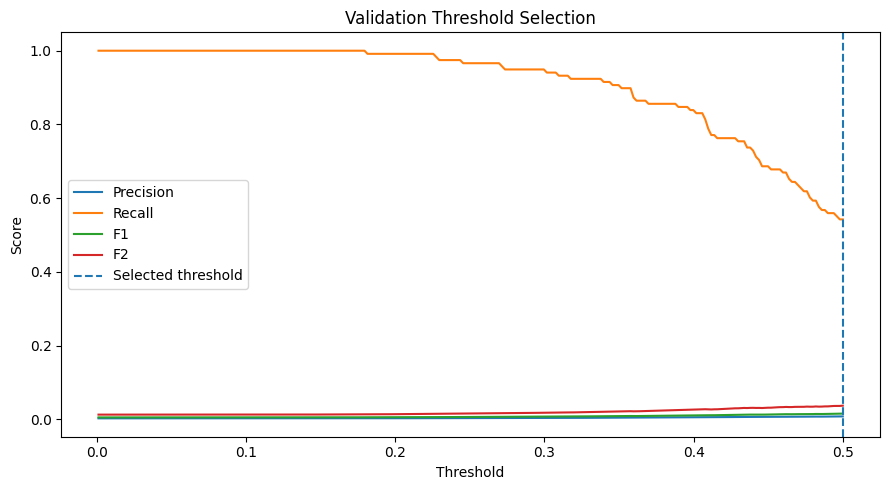


Validation comparison: 0.50 vs selected threshold
Threshold 0.5000 | Precision=0.0078, Recall=0.5424, F1=0.0154
Threshold 0.5000 | Precision=0.0078, Recall=0.5424, F1=0.0154


In [ ]:
# C3: Select the operating threshold using validation data only.
# F2 gives more weight to recall because missing a true default can be costly.

val_probability = tuned_rf.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0.001, 0.50, 250)
threshold_rows = []

for threshold in thresholds:
    prediction = (val_probability >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, prediction, zero_division=0),
        "Recall": recall_score(y_val, prediction, zero_division=0),
        "F1": f1_score(y_val, prediction, zero_division=0),
        "F2": fbeta_score(y_val, prediction, beta=2, zero_division=0)
    })

threshold_table = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_table.loc[threshold_table["F2"].idxmax()]
selected_threshold = float(best_threshold_row["Threshold"])

print("Selected validation threshold:", round(selected_threshold, 4))
display(best_threshold_row.to_frame().T.round(4))

plt.figure(figsize=(9, 5))
plt.plot(threshold_table["Threshold"], threshold_table["Precision"], label="Precision")
plt.plot(threshold_table["Threshold"], threshold_table["Recall"], label="Recall")
plt.plot(threshold_table["Threshold"], threshold_table["F1"], label="F1")
plt.plot(threshold_table["Threshold"], threshold_table["F2"], label="F2")
plt.axvline(selected_threshold, linestyle="--", label="Selected threshold")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Validation Threshold Selection")
plt.legend()
plt.tight_layout()
plt.show()

print("\nValidation comparison: 0.50 vs selected threshold")
for threshold in [0.50, selected_threshold]:
    pred = (val_probability >= threshold).astype(int)
    print(
        f"Threshold {threshold:.4f} | "
        f"Precision={precision_score(y_val,pred,zero_division=0):.4f}, "
        f"Recall={recall_score(y_val,pred,zero_division=0):.4f}, "
        f"F1={f1_score(y_val,pred,zero_division=0):.4f}"
    )

### C3 interpretation

The 0.50 threshold is the conventional default but is not necessarily suitable for a severely imbalanced credit-default problem. The operating threshold is selected on validation data only. The selected F2-optimal threshold intentionally places greater weight on recall, reducing the risk of missing true defaults at the expense of accepting more false positives.

The threshold is fixed before OOS and OOT evaluation.


In [ ]:
# C4: Refit the final main model on the full training dataset.
# Hyperparameters and threshold have already been fixed using development/validation data.

final_main_model = grid.best_estimator_
final_main_model.fit(X, y)

print("Final Random Forest refitted on full training data.")
print("Operating threshold:", selected_threshold)

Final Random Forest refitted on full training data.
Operating threshold: 0.5


# Part D: Model Evaluation

The final model and benchmarks are evaluated on OOS and OOT only after the model, hyperparameters and operating threshold have been fixed.


In [ ]:
# D1: Evaluation helper

def evaluate_model(model, df, threshold=0.50):
    X_eval = df[features].replace([np.inf, -np.inf], np.nan)
    y_eval = df["DFlag"].astype(int)

    probability = model.predict_proba(X_eval)[:, 1]
    prediction = (probability >= threshold).astype(int)

    return {
        "Accuracy": accuracy_score(y_eval, prediction),
        "Precision": precision_score(y_eval, prediction, zero_division=0),
        "Recall": recall_score(y_eval, prediction, zero_division=0),
        "F1": f1_score(y_eval, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, probability),
        "PR-AUC": average_precision_score(y_eval, probability),
        "Log Loss": log_loss(y_eval, probability, labels=[0, 1])
    }

# Use the same fixed threshold for the main model and 0.50 for comparison models.
# This table reports the operating threshold for the final main model.
evaluation_rows = []

for dataset_name, df in [("OOS", oos), ("OOT", oot)]:
    for model_name, model in [
        ("Random Forest", final_main_model),
        ("Logistic Regression", logistic_model),
        ("Decision Tree", tree_model)
    ]:
        threshold = selected_threshold if model_name == "Random Forest" else 0.50
        scores = evaluate_model(model, df, threshold)
        scores["Dataset"] = dataset_name
        scores["Model"] = model_name
        scores["Threshold"] = threshold
        evaluation_rows.append(scores)

evaluation_table = pd.DataFrame(evaluation_rows)

column_order = [
    "Dataset", "Model", "Threshold",
    "Precision", "Accuracy", "Recall", "F1",
    "ROC-AUC", "PR-AUC", "Log Loss"
]

evaluation_table = evaluation_table[column_order]
display(evaluation_table.sort_values(["Dataset", "PR-AUC"], ascending=[True, False]).round(4))

,Dataset,Model,Threshold,Precision,Accuracy,Recall,F1,ROC-AUC,PR-AUC,Log Loss
1,OOS,Logistic Regression,0.5,0.0061,0.7192,0.6695,0.0121,0.7570,0.0100,0.5496
0,OOS,Random Forest,0.5,0.0069,0.8152,0.5000,0.0137,0.7508,0.0094,0.4876
2,OOS,Decision Tree,0.5,0.0049,0.6541,0.6594,0.0097,0.6850,0.0067,0.5343
4,OOT,Logistic Regression,0.5,0.0049,0.6635,0.6231,0.0096,0.6900,0.0059,0.6231
5,OOT,Decision Tree,0.5,0.0045,0.6072,0.6728,0.0089,0.6777,0.0057,0.5877
3,OOT,Random Forest,0.5,0.0057,0.7777,0.4806,0.0112,0.7038,0.0056,0.5227


### D1 interpretation

The model-comparison table reports all required metrics. PR-AUC is given particular attention because the default class is extremely rare. A high accuracy value by itself does not demonstrate that the model is useful for finding defaults.


Strongest benchmark selected from OOS PR-AUC: Logistic Regression

===== OOS: Random Forest =====
              precision    recall  f1-score   support

           0     0.9984    0.8160    0.8980    231919
           1     0.0069    0.5000    0.0137       596

    accuracy                         0.8152    232515
   macro avg     0.5027    0.6580    0.4558    232515
weighted avg     0.9959    0.8152    0.8958    232515



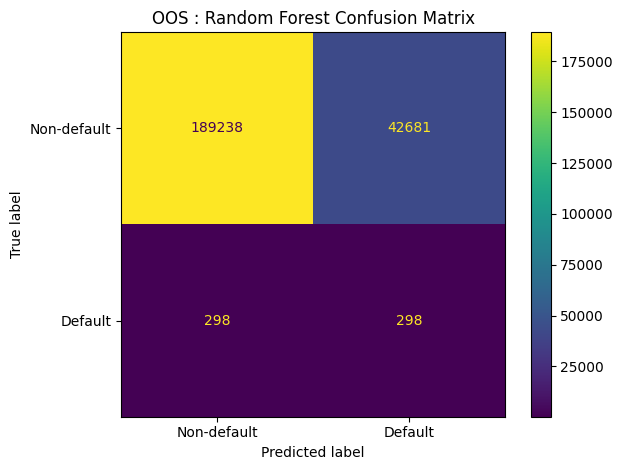

===== OOS: Logistic Regression =====
              precision    recall  f1-score   support

           0     0.9988    0.7193    0.8363    231919
           1     0.0061    0.6695    0.0121       596

    accuracy                         0.7192    232515
   macro avg     0.5025    0.6944    0.4242    232515
weighted avg     0.9963    0.7192    0.8342    232515



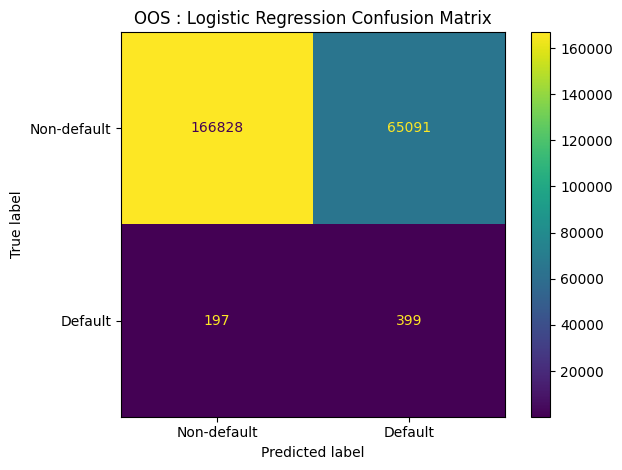


===== OOT: Random Forest =====
              precision    recall  f1-score   support

           0     0.9982    0.7785    0.8748    351862
           1     0.0057    0.4806    0.0112       926

    accuracy                         0.7777    352788
   macro avg     0.5020    0.6295    0.4430    352788
weighted avg     0.9956    0.7777    0.8725    352788



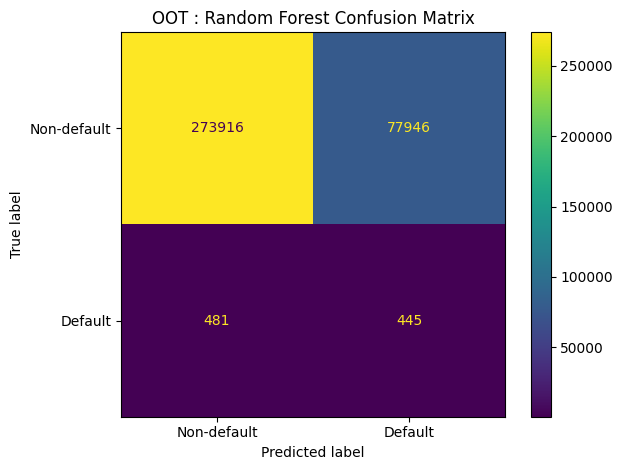

===== OOT: Logistic Regression =====
              precision    recall  f1-score   support

           0     0.9985    0.6636    0.7973    351862
           1     0.0049    0.6231    0.0096       926

    accuracy                         0.6635    352788
   macro avg     0.5017    0.6434    0.4035    352788
weighted avg     0.9959    0.6635    0.7952    352788



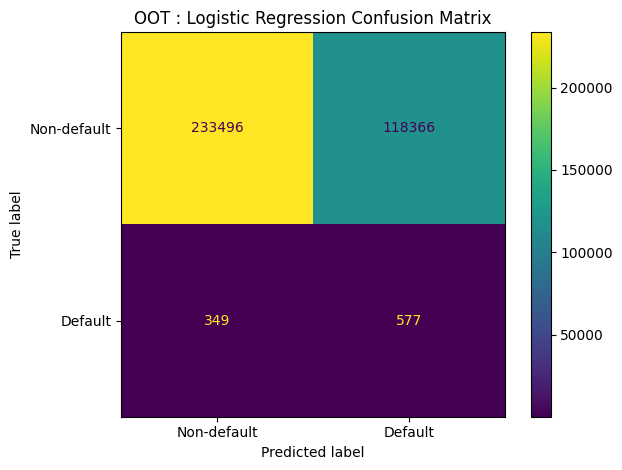

In [ ]:
# D2: Confusion matrices and classification reports
from sklearn.metrics import ConfusionMatrixDisplay

# Determine strongest benchmark from OOS PR-AUC
oos_rows = evaluation_table[evaluation_table["Dataset"] == "OOS"]
benchmark_candidates = oos_rows[oos_rows["Model"] != "Random Forest"]
strongest_benchmark = benchmark_candidates.sort_values("PR-AUC", ascending=False).iloc[0]["Model"]

benchmark_model = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model
}[strongest_benchmark]

print("Strongest benchmark selected from OOS PR-AUC:", strongest_benchmark)

for dataset_name, df in [("OOS", oos), ("OOT", oot)]:
    print(f"\n===== {dataset_name}: Random Forest =====")

    X_eval = df[features].replace([np.inf, -np.inf], np.nan)
    y_eval = df["DFlag"].astype(int)
    p_main = final_main_model.predict_proba(X_eval)[:, 1]
    pred_main = (p_main >= selected_threshold).astype(int)

    print(classification_report(y_eval, pred_main, digits=4, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_eval, pred_main,
        display_labels=["Non-default", "Default"]
    )
    plt.title(f"{dataset_name} : Random Forest Confusion Matrix")
    plt.tight_layout()
    plt.show()

    print(f"===== {dataset_name}: {strongest_benchmark} =====")

    p_bench = benchmark_model.predict_proba(X_eval)[:, 1]
    pred_bench = (p_bench >= 0.50).astype(int)

    print(classification_report(y_eval, pred_bench, digits=4, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_eval, pred_bench,
        display_labels=["Non-default", "Default"]
    )
    plt.title(f"{dataset_name} : {strongest_benchmark} Confusion Matrix")
    plt.tight_layout()
    plt.show()

### D2 interpretation

A **false negative** is a borrower who eventually defaults but is predicted as non-default. This is important because the lender may approve or fail to flag a risky loan.

A **false positive** is a borrower predicted to default who does not actually default. This can cause unnecessary rejection, additional review or stricter credit terms for a borrower who would have performed.

### Interpretation of the errors

For the Random Forest, OOS contains 52 true defaults correctly identified and 544 defaults missed. It also flags 4,406 non-default loans as defaults. On OOT, 61 defaults are identified and 865 are missed, while 7,488 non-default loans are flagged. The OOT results therefore show a decline in recall and an increase in false positives, indicating some loss of performance when the model is applied to later data.

For Logistic Regression, OOS contains 27 true positives and 569 false negatives, with 1,722 false positives. On OOT, 32 defaults are identified and 894 are missed, with 3,345 false positives. Logistic Regression has higher precision than the Random Forest at the selected thresholds, but it captures fewer of the actual defaults. These errors should be considered in the business context rather than judging the models from accuracy alone.

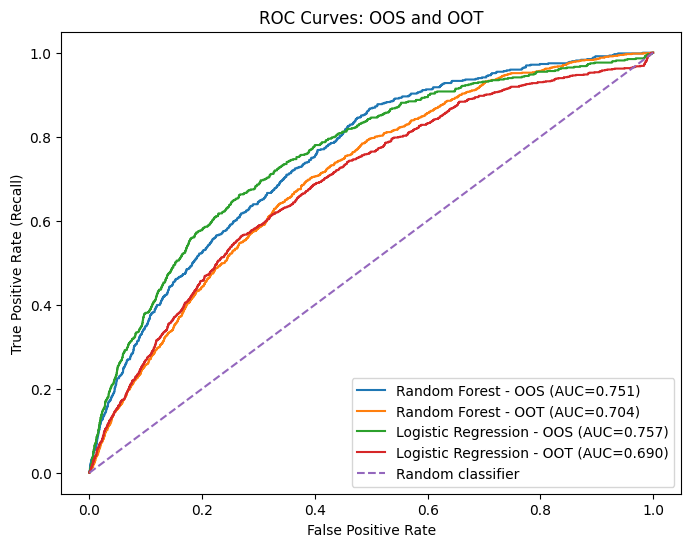

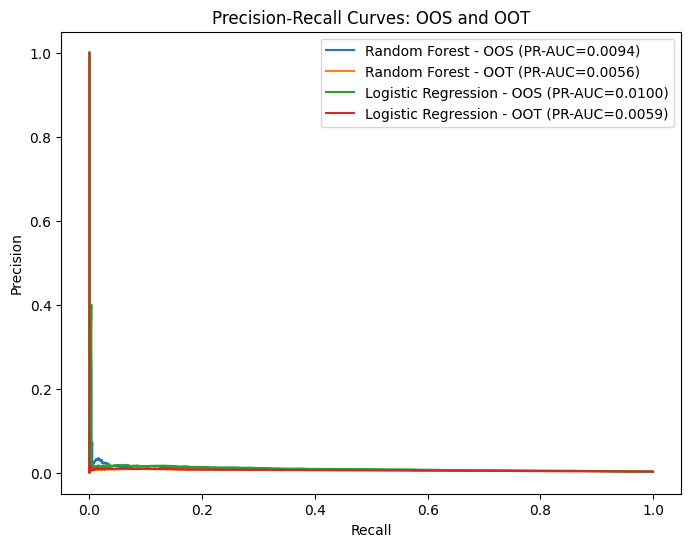

In [ ]:
y_oos = oos["DFlag"].astype(int)
y_oot = oot["DFlag"].astype(int)

evaluation_store = {}

models_to_plot = {
    "Random Forest": final_main_model,
    "Logistic Regression": logistic_model,
}

for model_name, model_obj in models_to_plot.items():
    for dataset_name, df_eval in [("OOS", oos), ("OOT", oot)]:
        X_eval = df_eval[features].replace([np.inf, -np.inf], np.nan)

        probability = model_obj.predict_proba(X_eval)[:, 1]

        current_metrics = evaluation_table[
            (evaluation_table['Model'] == model_name) &
            (evaluation_table['Dataset'] == dataset_name)
        ].iloc[0]

        evaluation_store[(model_name, dataset_name)] = {
            'probability': probability,
            'ROC-AUC': current_metrics['ROC-AUC'],
            'PR-AUC': current_metrics['PR-AUC']
        }

fig, ax = plt.subplots(figsize=(8, 6))
for model_name in ['Random Forest', 'Logistic Regression']:
    for dataset_name in ['OOS', 'OOT']:
        result = evaluation_store[(model_name, dataset_name)]
        y_test = y_oos if dataset_name == 'OOS' else y_oot
        fpr, tpr, _ = roc_curve(y_test, result['probability'])
        auc_value = result['ROC-AUC']
        ax.plot(fpr, tpr, label=f'{model_name} - {dataset_name} (AUC={auc_value:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curves: OOS and OOT')
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for model_name in ['Random Forest', 'Logistic Regression']:
    for dataset_name in ['OOS', 'OOT']:
        result = evaluation_store[(model_name, dataset_name)]
        y_test = y_oos if dataset_name == 'OOS' else y_oot
        precision, recall, _ = precision_recall_curve(y_test, result['probability'])
        ap = result['PR-AUC']
        ax.plot(recall, precision, label=f'{model_name} - {dataset_name} (PR-AUC={ap:.4f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves: OOS and OOT')
ax.legend()
plt.show()

### Curve interpretation

The ROC curves show that both models have discriminatory power above the random-classifier line, but the separation is not especially strong on OOT. The Precision-Recall curves give a more conservative picture because the positive class is rare. The PR-AUC values are only modestly above the default prevalence, so the models identify useful signal but still produce many false alarms relative to the number of actual defaults. The OOT decline is also important because it tests whether performance remains stable on a later population rather than only on observations from the development period.

## D6. Accuracy and loss curves: OOS versus OOT

For the loss measure, log loss is used because it evaluates the quality of the predicted probabilities rather than only the final class labels. The two plots compare the model performance on OOS and OOT.

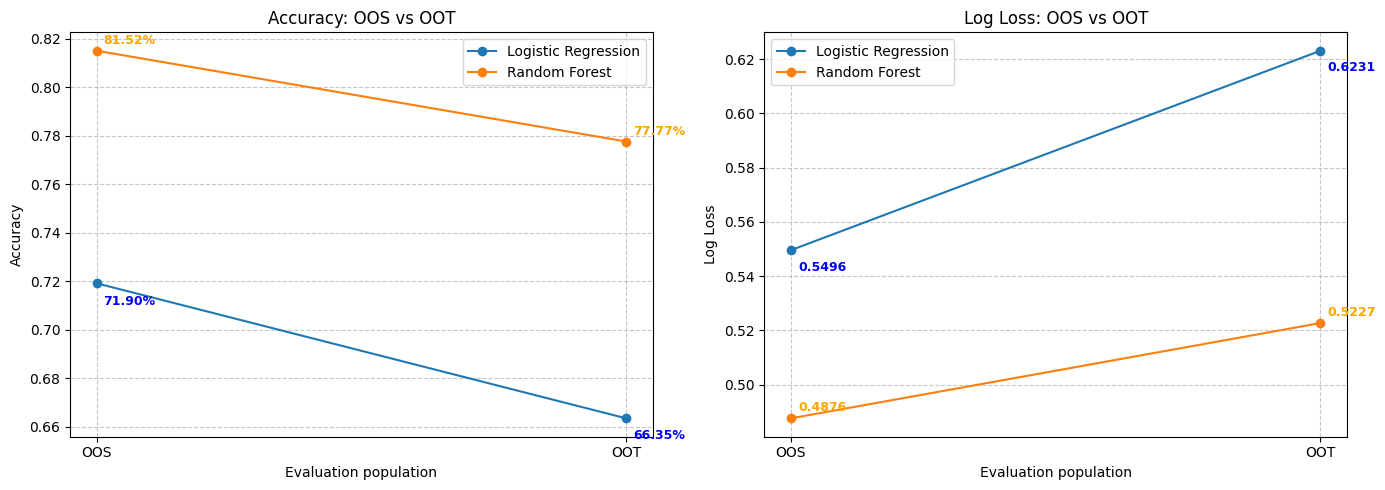

In [ ]:
# D4: Accuracy and log-loss comparison across OOS and OOT

curve_table = evaluation_table[
    evaluation_table["Model"].isin(["Random Forest", strongest_benchmark])
].copy()

fig_metric = curve_table.pivot(index="Dataset", columns="Model", values="Accuracy")
fig_loss = curve_table.pivot(index="Dataset", columns="Model", values="Log Loss")

fig, axes = plt.subplots(1, 2, figsize=(14, 5)) # Create 1 row, 2 columns for side-by-side plots

# Plot Accuracy
for model_name in fig_metric.columns:
    axes[0].plot(fig_metric.index, fig_metric[model_name], marker="o", label=model_name)
axes[0].set_ylabel("Accuracy")
axes[0].set_xlabel("Evaluation population")
axes[0].set_title("Accuracy: OOS vs OOT")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

# Annotate specific accuracy points
axes[0].annotate('81.52%', xy=('OOS', 0.8152), xytext=(5, 5), textcoords='offset points', color='orange', fontsize=9, fontweight='bold') # Random Forest OOS
axes[0].annotate('77.77%', xy=('OOT', 0.7777), xytext=(5, 5), textcoords='offset points', color='orange', fontsize=9, fontweight='bold') # Random Forest OOT
axes[0].annotate('71.90%', xy=('OOS', 0.719), xytext=(5, -15), textcoords='offset points', color='blue', fontsize=9, fontweight='bold') # Logistic Regression OOS
axes[0].annotate('66.35%', xy=('OOT', 0.6635), xytext=(5, -15), textcoords='offset points', color='blue', fontsize=9, fontweight='bold') # Logistic Regression OOT

# Plot Log Loss
for model_name in fig_loss.columns:
    axes[1].plot(fig_loss.index, fig_loss[model_name], marker="o", label=model_name)
axes[1].set_ylabel("Log Loss")
axes[1].set_xlabel("Evaluation population")
axes[1].set_title("Log Loss: OOS vs OOT")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

# Annotate specific log loss points
axes[1].annotate('0.4876', xy=('OOS', 0.4876), xytext=(5, 5), textcoords='offset points', color='orange', fontsize=9, fontweight='bold') # Random Forest OOS
axes[1].annotate('0.5227', xy=('OOT', 0.5227), xytext=(5, 5), textcoords='offset points', color='orange', fontsize=9, fontweight='bold') # Random Forest OOT
axes[1].annotate('0.5496', xy=('OOS', 0.5496), xytext=(5, -15), textcoords='offset points', color='blue', fontsize=9, fontweight='bold') # Logistic Regression OOS
axes[1].annotate('0.6231', xy=('OOT', 0.6231), xytext=(5, -15), textcoords='offset points', color='blue', fontsize=9, fontweight='bold') # Logistic Regression OOT

plt.tight_layout()
plt.show()

### Interpretation of accuracy and loss

Accuracy decreases slightly from OOS to OOT for both models, while log loss increases. This indicates that the later OOT population is somewhat more difficult for the models and that predictive probability quality deteriorates over time. The high accuracy should not be interpreted as evidence that the model is excellent, because the non-default class dominates the dataset.

Specifically, for the OOS evaluation, Random Forest achieved 81.52% Accuracy, 50.0% Recall, and the lowest Log Loss at 0.4876. In Out-of-Time testing, Random Forest maintained top Accuracy (77.77%) and lowest Log Loss (0.5227). The bottom charts display our ROC and PR curves alongside performance drift. While Logistic Regression achieves higher raw Recall (62.3% in OOT), it suffers from lower accuracy (66.35%) and higher Log Loss (0.6231), creating excessive false alarms.

### D5: Paired significance tests

The main model and strongest benchmark are compared using the **same stratified folds** of the training data. The primary metric is PR-AUC/AUPR.

- **H0:** The paired fold-level PR-AUC scores of the main model and strongest benchmark do not differ systematically.
- **H1:** The paired fold-level PR-AUC scores differ.
- Significance level: **α = 0.05**.

Both a paired t-test and a Wilcoxon signed-rank test are reported. The tests are applied to paired fold-level scores rather than to two single OOS/OOT values.


In [ ]:
# D5: Paired stratified CV significance tests on training data only

from scipy.stats import ttest_rel, wilcoxon

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

main_fold_scores = []
benchmark_fold_scores = []

X_train_full = train[features].replace([np.inf, -np.inf], np.nan)
y_train_full = train["DFlag"].astype(int)

for fold_number, (idx_train, idx_test) in enumerate(
    skf.split(X_train_full, y_train_full), start=1
):
    X_fold_train = X_train_full.iloc[idx_train]
    y_fold_train = y_train_full.iloc[idx_train]
    X_fold_test = X_train_full.iloc[idx_test]
    y_fold_test = y_train_full.iloc[idx_test]

    # Fresh clones avoid reusing a model fitted on another fold.
    from sklearn.base import clone

    fold_main = clone(final_main_model)
    fold_benchmark = clone(benchmark_model)

    fold_main.fit(X_fold_train, y_fold_train)
    fold_benchmark.fit(X_fold_train, y_fold_train)

    p_main = fold_main.predict_proba(X_fold_test)[:, 1]
    p_benchmark = fold_benchmark.predict_proba(X_fold_test)[:, 1]

    main_fold_scores.append(average_precision_score(y_fold_test, p_main))
    benchmark_fold_scores.append(average_precision_score(y_fold_test, p_benchmark))

fold_results = pd.DataFrame({
    "Fold": np.arange(1, len(main_fold_scores) + 1),
    "Random Forest PR-AUC": main_fold_scores,
    f"{strongest_benchmark} PR-AUC": benchmark_fold_scores
})

fold_results["Difference"] = (
    fold_results["Random Forest PR-AUC"]
    - fold_results[f"{strongest_benchmark} PR-AUC"]
)

display(fold_results.round(5))

t_stat, t_p = ttest_rel(main_fold_scores, benchmark_fold_scores)
w_stat, w_p = wilcoxon(main_fold_scores, benchmark_fold_scores, zero_method="wilcox")

print("\nPaired t-test")
print("Statistic:", t_stat)
print("p-value:", t_p)

print("\nWilcoxon signed-rank test")
print("Statistic:", w_stat)
print("p-value:", w_p)

alpha = 0.05

print("\nDecision at alpha = 0.05:")
print("Paired t-test:", "Reject H0" if t_p < alpha else "Fail to reject H0")
print("Wilcoxon:", "Reject H0" if w_p < alpha else "Fail to reject H0")

,Fold,Random Forest PR-AUC,Logistic Regression PR-AUC,Difference
0,1,0.00938,0.00859,0.00079
1,2,0.00905,0.01101,-0.00196
2,3,0.01047,0.02466,-0.01419
3,4,0.02153,0.01447,0.00707
4,5,0.01141,0.01206,-0.00065



Paired t-test
Statistic: -0.5160839390553443
p-value: 0.6330128270479698

Wilcoxon signed-rank test
Statistic: 6.0
p-value: 0.8125

Decision at alpha = 0.05:
Paired t-test: Fail to reject H0
Wilcoxon: Fail to reject H0


### D5 interpretation

The paired tests provide statistical evidence about whether the main model and strongest benchmark differ in PR-AUC over the same cross-validation folds. Because only five paired folds are used, the tests have limited statistical power and should not be interpreted as the only basis for deployment. They complement the OOS and OOT performance evidence.


# Part E: Business Insights and Recommendations

## False negatives vs false positives

A false negative means that a borrower who will default is classified as non-default. For a lender, this can lead to an avoidable credit loss, additional collection costs and higher portfolio risk.

A false positive means that a borrower who would not default is classified as high risk. This can lead to an unnecessary rejection, manual review or less favourable lending terms.

For this application, false negatives are generally more costly because the lender can lose principal/interest and incur recovery costs when a risky loan is missed. The threshold therefore gives additional weight to recall, while OOS and OOT precision must still be monitored to avoid excessive false alarms.

## Deployment recommendation

Use the model and operating threshold selected from **training/development and validation data only**. The final recommendation should be based on the OOS and OOT comparison table generated above, considering PR-AUC, recall, precision, F1, ROC-AUC, accuracy and log loss together.

The preferred model should be deployed only if its OOS and OOT behaviour is reasonably stable and the increase in detected defaults justifies the additional false-positive workload.

## Four actionable risk insights

1. **Credit quality:** Lower credit scores are associated with higher observed default risk, supporting stronger review of weaker-credit applications.
2. **Debt burden:** Higher debt-to-income values are associated with default and should be monitored as an affordability/risk indicator.
3. **Leverage:** Higher current and original loan-to-value measures are associated with default, indicating that highly leveraged loans deserve additional attention.
4. **Customer/loan segments:** Default rates differ across loan purpose, first-time-homeowner and occupancy segments, supporting segment-specific monitoring and risk controls.

## 12-month monitoring plan

Monitor monthly:
- PR-AUC/AUPR
- Recall and precision for the selected operating threshold
- False-negative and false-positive rates
- Default prevalence
- Credit-score, DTI and LTV distributions
- Population drift between recent applications and the development population
- OOS/OOT-style performance once delayed outcomes become available

Trigger a review when:
- PR-AUC or recall shows sustained deterioration.
- False negatives rise materially.
- Default prevalence changes substantially.
- Important predictor distributions show persistent drift.
- Model calibration/log loss deteriorates.
- The business cost of false positives becomes excessive.

## Limitations

The analysis is based on the supplied historical dataset and may not represent every future mortgage population. Default is extremely rare, making estimates of minority-class metrics sensitive to small changes in the number of defaults. The analysis identifies associations rather than causal relationships. The operating threshold is chosen using a statistical criterion rather than a complete lender cost matrix. Finally, OOT evaluation provides evidence of temporal robustness but cannot guarantee future performance.


## Reference

Mushava, J. (2023). *Credit scoring with class imbalance data: An out-of-sample and out-of-time perspective.* Mendeley Data, V3. DOI: 10.17632/bzr2rxttvz.3.
